# Insurance Claims: Exploratory Analysis & Hypothesis Testing
**Author:** Amal Shesnij

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.float_format', '{:,.2f}'.format)

claims = pd.read_csv('claims.csv')
cust = pd.read_csv('cust_demographics.csv')

print('Claims   :', claims.shape)
print('Customers:', cust.shape)
print('Duplicate customer IDs in claims:', claims['customer_id'].duplicated().sum())
print('Claims with no matching customer:', (~claims['customer_id'].isin(cust['CUST_ID'])).sum())
print('Customers with no claims        :', (~cust['CUST_ID'].isin(claims['customer_id'])).sum())

Claims   : (1100, 10)
Customers: (1085, 6)
Duplicate customer IDs in claims: 7
Claims with no matching customer: 15
Customers with no claims        : 7


## Q1. Merge the datasets (inner join: keep only claims with customer details)

In [2]:
df = cust.merge(claims, left_on='CUST_ID', right_on='customer_id', how='inner')
df = df.drop(columns='customer_id')
print(df.shape)
df.head()

(1085, 15)


,CUST_ID,gender,DateOfBirth,State,Contact,Segment,claim_id,incident_cause,claim_date,claim_area,police_report,claim_type,claim_amount,total_policy_claims,fraudulent
0,21868593,Female,12-Jan-79,VT,789-916-8172,Platinum,54004764,Driver error,11/27/2017,Auto,No,Material only,$2980,1.00,No
1,75740424,Female,13-Jan-70,ME,265-543-1264,Silver,33985796,Crime,10/03/2018,Home,Unknown,Material only,$2980,3.00,No
2,30308357,Female,11-Mar-84,TN,798-631-4758,Silver,53522022,Other driver error,02/02/2018,Auto,No,Material only,$3369.5,1.00,Yes
3,30308357,Female,11-Mar-84,TN,798-631-4758,Silver,63017412,Driver error,04/04/2018,Auto,No,Material only,$1950,6.00,No
4,47830476,Female,01-May-86,MA,413-187-7945,Silver,13015401,Natural causes,06/17/2018,Auto,No,Material only,$1680,1.00,No


## Q2. Data audit

In [3]:
df.dtypes

CUST_ID                  int64
gender                     str
DateOfBirth                str
State                      str
Contact                    str
Segment                    str
claim_id                 int64
incident_cause             str
claim_date                 str
claim_area                 str
police_report              str
claim_type                 str
claim_amount               str
total_policy_claims    float64
fraudulent                 str
dtype: object

**Data type issues:** `claim_amount` is text (contains "$") but should be numeric; `claim_date` and `DateOfBirth` are text but should be dates; `CUST_ID` and `claim_id` are identifiers stored as numbers; `total_policy_claims` is a decimal but is a count.

## Q3–Q4. Fix amounts and dates; unreported injury flag

In [4]:
df['claim_amount'] = pd.to_numeric(df['claim_amount'].str.replace('$', '', regex=False))
df['claim_date'] = pd.to_datetime(df['claim_date'], format='%m/%d/%Y')
df['DateOfBirth'] = pd.to_datetime(df['DateOfBirth'], format='%d-%b-%y')

future = df['DateOfBirth'].dt.year > 2018
print('Future birth years before fix:', future.sum())
df.loc[future, 'DateOfBirth'] = df.loc[future, 'DateOfBirth'] - pd.DateOffset(years=100)
print('Future birth years after fix :', (df['DateOfBirth'].dt.year > 2018).sum())

df['unreported_injury_flag'] = np.where(
    df['claim_type'].str.contains('injury', case=False) & (df['police_report'] != 'Yes'), 1, 0)
print('Unreported injury claims:', df['unreported_injury_flag'].sum())

Future birth years before fix: 245
Future birth years after fix : 0
Unreported injury claims: 297


## Q5–Q7. Duplicates, missing values, age groups

In [5]:
print('Rows before:', len(df))
df = df.sort_values('claim_date').drop_duplicates('CUST_ID', keep='last')
print('Rows after :', len(df))

print('\nMissing before:\n', df.isnull().sum()[df.isnull().sum() > 0])
df['claim_amount'] = df['claim_amount'].fillna(df['claim_amount'].mean())
df['total_policy_claims'] = df['total_policy_claims'].fillna(df['total_policy_claims'].mode()[0])
print('Missing after:', df.isnull().sum().sum())

ref_date = df['claim_date'].max()
df['Age'] = ((ref_date - df['DateOfBirth']).dt.days / 365.25).astype(int)
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 18, 30, 60, 200],
                         labels=['Children', 'Youth', 'Adult', 'Senior'], right=False)
print('\nAge range:', df['Age'].min(), 'to', df['Age'].max())
print(df['Age_Group'].value_counts())

Rows before: 1085
Rows after : 1078

Missing before:
 claim_amount           65
total_policy_claims    10
dtype: int64
Missing after: 0

Age range: 18 to 58
Age_Group
Adult       769
Youth       309
Children      0
Senior        0
Name: count, dtype: int64


**Conclusion (Q1–Q7):** The datasets were joined with an inner join (1,085 rows). Claim amounts were converted from text to numbers, and 245 birth dates that two-digit years had placed in the future (e.g. 2068) were moved back 100 years. 297 injury claims were not reported to the police ("No" or "Unknown") and are flagged. 7 duplicate customers were removed, keeping each customer's most recent claim (1,078 rows). 65 missing claim amounts were filled with the mean and 10 missing policy counts with the mode. Customers are aged 18–58: 769 Adults and 309 Youth, with no Children or Seniors.

## Q8. Average claim amount by segment

In [6]:
df.groupby('Segment')['claim_amount'].mean().round(2)

Segment
Gold       12,846.40
Platinum   12,371.65
Silver     12,267.86
Name: claim_amount, dtype: float64

## Q9. Total claim amount by incident cause (claims at least 20 days before 1 Oct 2018)

In [7]:
cutoff = pd.Timestamp('2018-10-01') - pd.Timedelta(days=20)
print('Cut-off date:', cutoff.date())
df[df['claim_date'] <= cutoff].groupby('incident_cause')['claim_amount'].sum().sort_values(ascending=False)

Cut-off date: 2018-09-11


incident_cause
Other causes         3,723,151.80
Driver error         3,315,850.72
Other driver error   3,277,536.45
Natural causes       1,312,987.04
Crime                  721,938.63
Name: claim_amount, dtype: float64

## Q10. Adults from TX, DE and AK with driver-related claims

In [8]:
q10 = df[(df['Age_Group'] == 'Adult') &
         (df['State'].isin(['TX', 'DE', 'AK'])) &
         (df['incident_cause'].str.contains('driver', case=False))]
print('Number of adults:', len(q10))
q10.groupby('State').size()

Number of adults: 25


State
AK     8
DE    10
TX     7
dtype: int64

**Conclusion (Q8–Q10):** Average claims are almost the same across segments (Gold ≈ 12,846, Platinum ≈ 12,372, Silver ≈ 12,268). For claims made at least 20 days before 1 October 2018, "Other causes" has the highest total, followed by driver error and other-driver error. 25 adults from TX, DE and AK made driver-related claims.

## Q11. Claim amount by gender and segment

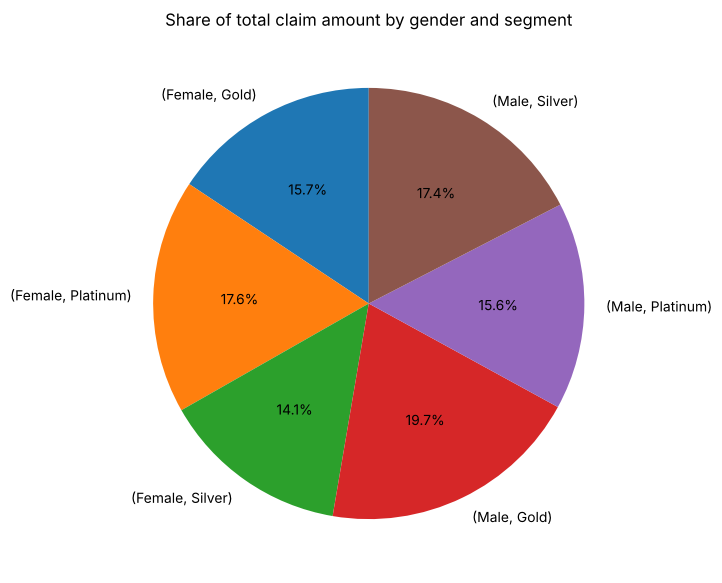

gender  Segment 
Female  Gold       2,110,044.54
        Platinum   2,369,722.09
        Silver     1,897,544.95
Male    Gold       2,655,969.95
        Platinum   2,096,445.31
        Silver     2,347,134.40
Name: claim_amount, dtype: float64

In [9]:
gs = df.groupby(['gender', 'Segment'])['claim_amount'].sum()
gs.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7), ylabel='', startangle=90)
plt.title('Share of total claim amount by gender and segment'); plt.show()
gs

## Q12. Driver-related claims by gender

,count,sum
gender,,
Female,221,"3,136,717.95"
Male,281,"3,975,411.85"


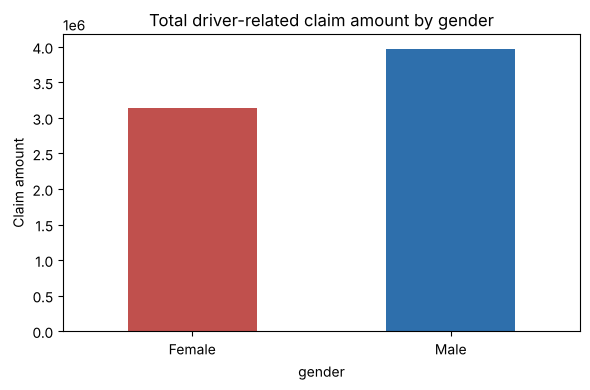

In [10]:
driver = df[df['incident_cause'].str.contains('driver', case=False)]
q12 = driver.groupby('gender')['claim_amount'].agg(['count', 'sum'])
display(q12)
q12['sum'].plot(kind='bar', color=['#C0504D', '#2E6FAC'], figsize=(6, 4))
plt.title('Total driver-related claim amount by gender'); plt.ylabel('Claim amount')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Q13. Fraudulent claims by age group

Age_Group
Adult    177
Youth     68
Name: count, dtype: int64


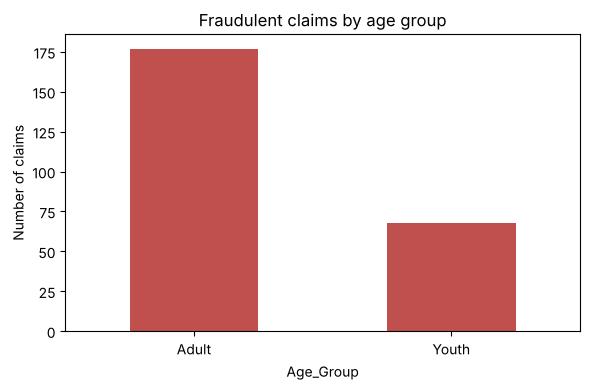

In [11]:
fraud_age = df[df['fraudulent'] == 'Yes']['Age_Group'].value_counts()
fraud_age = fraud_age[fraud_age > 0]
print(fraud_age)
fraud_age.plot(kind='bar', color='#C0504D', figsize=(6, 4))
plt.title('Fraudulent claims by age group'); plt.ylabel('Number of claims')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Q14. Monthly trend of total claim amount

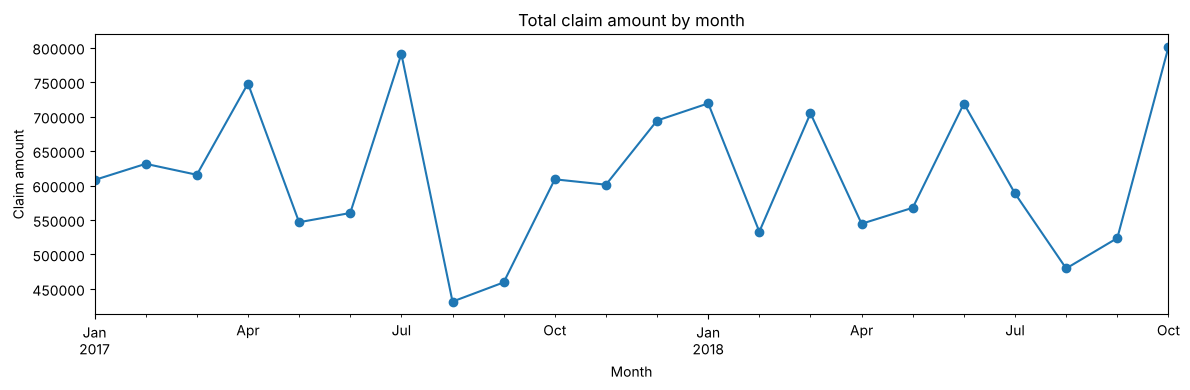

In [12]:
monthly = df.groupby(df['claim_date'].dt.to_period('M'))['claim_amount'].sum()
monthly.plot(figsize=(12, 4), marker='o')
plt.title('Total claim amount by month'); plt.ylabel('Claim amount'); plt.xlabel('Month')
plt.tight_layout(); plt.show()

## Q15. Average claim by gender and age group: fraudulent vs non-fraudulent

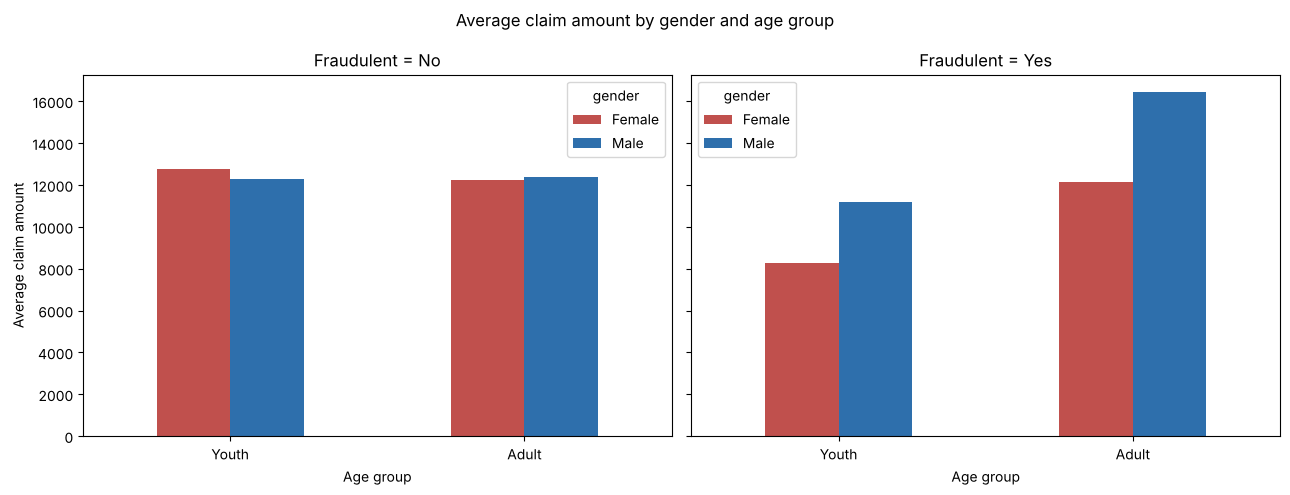

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, f in zip(axes, ['No', 'Yes']):
    data = df[df['fraudulent'] == f].pivot_table(index='Age_Group', columns='gender',
                                                  values='claim_amount', aggfunc='mean', observed=True)
    data.plot(kind='bar', ax=ax, color=['#C0504D', '#2E6FAC'])
    ax.set_title(f'Fraudulent = {f}'); ax.set_xlabel('Age group'); ax.tick_params(axis='x', rotation=0)
axes[0].set_ylabel('Average claim amount')
plt.suptitle('Average claim amount by gender and age group'); plt.tight_layout(); plt.show()

**Conclusion (Q11–Q15):**
- Claim amounts are split fairly evenly across gender and segment combinations (Q11).
- Men claimed more for driver-related issues: about 3.98M across 281 claims, against 3.14M across 221 claims for women (Q12).
- Adults made the most fraudulent claims (177), against 68 for Youth (Q13). Adults are also the larger group, so this partly reflects group size.
- Monthly claim totals fluctuate, with the months shown in date order (Q14).
- Non-fraudulent claims average about the same across gender and age. Among fraudulent claims, adult men have the highest average claim (about 16,500), so high-value claims from adult men deserve closer review (Q15).

## Q16–Q20. Hypothesis tests (significance level = 0.05)

In [14]:
def decide(p):
    return 'Reject H0 (significant)' if p < 0.05 else 'Fail to reject H0 (not significant)'

# Q16. Do males and females claim similar amounts?  -> independent t-test
male = df.loc[df['gender'] == 'Male', 'claim_amount']
female = df.loc[df['gender'] == 'Female', 'claim_amount']
t, p16 = stats.ttest_ind(male, female, equal_var=False)
print(f'Q16  Male mean {male.mean():,.0f} vs Female mean {female.mean():,.0f} | p = {p16:.4f} -> {decide(p16)}')

# Q17. Is age category related to segment?  -> chi-square test of independence
table = pd.crosstab(df['Age_Group'], df['Segment'])
chi2, p17, dof, _ = stats.chi2_contingency(table)
print(f'Q17  Chi-square p = {p17:.4f} -> {decide(p17)}')

# Q18. Are 2018 claims higher than the 2016-17 average of $10,000?  -> one-sample t-test
current = df.loc[df['claim_date'].dt.year == 2018, 'claim_amount']
t, p18 = stats.ttest_1samp(current, 10000, alternative='greater')
print(f'Q18  2018 mean {current.mean():,.0f} (n = {len(current)}) vs 10,000 | p = {p18:.2e} -> {decide(p18)}')

# Q19. Do age groups claim different amounts?  -> t-test (only Youth and Adult exist)
youth = df.loc[df['Age_Group'] == 'Youth', 'claim_amount']
adult = df.loc[df['Age_Group'] == 'Adult', 'claim_amount']
t, p19 = stats.ttest_ind(youth, adult, equal_var=False)
print(f'Q19  Youth mean {youth.mean():,.0f} vs Adult mean {adult.mean():,.0f} | p = {p19:.4f} -> {decide(p19)}')

# Q20. Is the number of policy claims related to the claim amount?  -> correlation
r, p20 = stats.pearsonr(df['total_policy_claims'], df['claim_amount'])
print(f'Q20  r = {r:.3f} | p = {p20:.4f} -> {decide(p20)}')

Q16  Male mean 12,885 vs Female mean 12,101 | p = 0.3357 -> Fail to reject H0 (not significant)
Q17  Chi-square p = 0.4535 -> Fail to reject H0 (not significant)
Q18  2018 mean 12,743 (n = 485) vs 10,000 | p = 4.72e-06 -> Reject H0 (significant)
Q19  Youth mean 11,913 vs Adult mean 12,738 | p = 0.3528 -> Fail to reject H0 (not significant)
Q20  r = -0.022 | p = 0.4625 -> Fail to reject H0 (not significant)


### Hypothesis test results (significance level α = 0.05)

**Q16. Do males and females claim similar amounts?**
- H0: mean claim (male) = mean claim (female). H1: the means differ.
- Test: Welch's two-sample t-test (two independent groups, unequal variances).
- Result: male 12,885 vs female 12,101, p = 0.34 > 0.05, so we fail to reject H0.
- Implication: claim amounts are similar for both genders; gender is not a basis for pricing.

**Q17. Is age category related to segment?**
- H0: age group and segment are independent. H1: they are related.
- Test: chi-square test of independence (two categorical variables).
- Result: p = 0.45 > 0.05, so we fail to reject H0.
- Implication: segments contain a similar age mix; segment offers need not be age-targeted.

**Q18. Have claim amounts risen above the 2016–17 average of $10,000?**
- H0: mean 2018 claim ≤ 10,000. H1: mean 2018 claim > 10,000.
- Test: one-sample t-test (one-sided, one group against a fixed value).
- Result: 2018 mean 12,743 (n = 485), p < 0.001, so we reject H0.
- Implication: claims are about 27% above the previous average; reserves and premiums should be reviewed.

**Q19. Do age groups claim different amounts?**
- H0: mean claim (Youth) = mean claim (Adult). H1: the means differ.
- Test: Welch's t-test (only two age groups exist in the data, so ANOVA is not needed).
- Result: Youth 11,913 vs Adult 12,738, p = 0.35 > 0.05, so we fail to reject H0.
- Implication: age group does not drive claim size.

**Q20. Is the number of policy claims related to the claimed amount?**
- H0: no correlation. H1: there is a correlation.
- Test: Pearson correlation (two numeric variables).
- Result: r = −0.02, p = 0.46 > 0.05, so we fail to reject H0.
- Implication: customers with more past claims do not make larger claims; claim history alone should not set claim limits.

## Key Findings
1. **Data quality:** two-digit birth years placed 245 customers in the future; these were corrected. 297 injury claims were not reported to the police and are flagged.
2. **Customers:** all customers are aged 18–58 (769 Adults, 309 Youth).
3. **Segments:** average claims are almost identical across Gold, Platinum and Silver (about 12,300–12,850).
4. **Driver-related claims:** men claimed more (about 3.98M vs 3.14M for women).
5. **Fraud:** adults made 177 of 245 fraudulent claims; fraudulent claims by adult men have the highest average (about 16,500).
6. **Claims are rising:** the 2018 average claim (12,743) is significantly above the 2016–17 average of 10,000 (p < 0.001).
7. **No significant effect** of gender, age group or segment on claim size, and no link between the number of past claims and claim amount.

## Business implications
- Review reserves and premiums, as claims are about 27% above the previous average.
- Gender, age and segment alone do not justify different pricing.
- Prioritise high-value claims from adult men and unreported injury claims for fraud review.

## Assumptions
- Inner join used for the 360-degree view (15 claims without customer records were excluded).
- "Unknown" police reports were treated as not reported.
- Age was calculated at the latest claim date in the data.
- "Current year" in Q18 was taken as 2018, the latest year in the data.